# Example on 1D Function Approximation Using SDN
Considering two functions: a high-fidelity (HF) function and a low-fidelity (LF) function, whose shape is

$$ 
u_{LF} = \sin(\mu \pi x) \qquad \qquad u_{HF} = u_{LF} \cdot e^{-5 \cdot (x-\mu)^2}
$$

Tier B baselines (Linear-MF, GP-residual, Co-kriging) are included as a **code sanity check**. 
For a case where GP-residual struggles, see `ExampleMF1D_HighFreqCorrection.ipynb`.


Text(0, 0.5, 'u_LF(x, mu)')

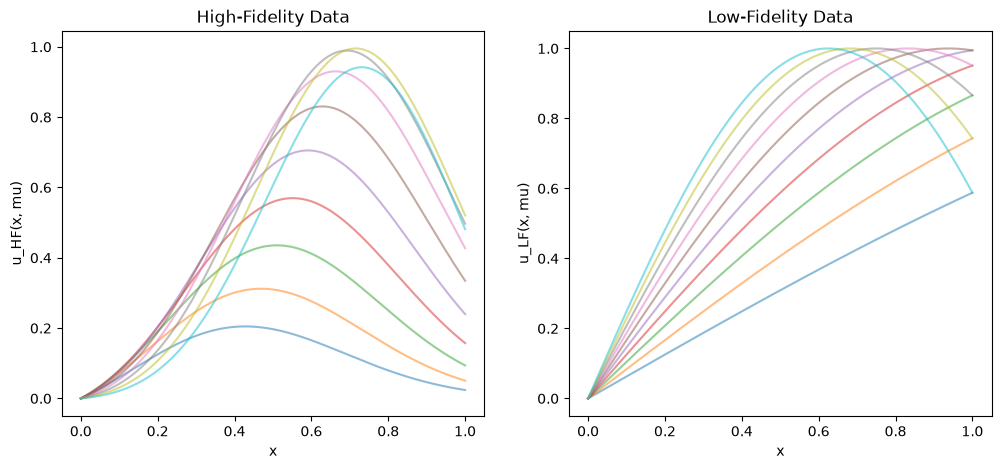

In [1]:
import numpy as np

def u_LF(x, mu):
    return np.sin(mu * np.pi * x)

def u_HF(x, mu):
    return u_LF(x, mu) * np.exp(-5 * (x - mu)**2) 

# Sampling
x = np.linspace(0, 1, 256)
mu_example = np.linspace(0.2, 0.8, 10)

U_HF = np.stack([u_HF(x, mu) for mu in mu_example]) 
U_LF = np.stack([u_LF(x, mu) for mu in mu_example])


import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].plot(x, U_HF.T, alpha=0.5)
axs[0].set_title('High-Fidelity Data')
axs[0].set_xlabel('x')
axs[0].set_ylabel('u_HF(x, mu)')

axs[1].plot(x, U_LF.T, alpha=0.5)
axs[1].set_title('Low-Fidelity Data')
axs[1].set_xlabel('x')
axs[1].set_ylabel('u_LF(x, mu)')

## Low Fidelity Surrogate Model

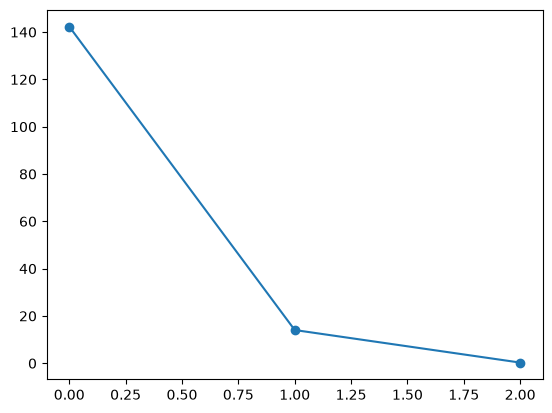

Training done: Training MRE = 0.63% 	 Validation MRE = 0.45%      


/Users/rivas/Github/SDN4Neutronics/utils/sdn.py:10: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:823.)
  num2p = lambda prob : ("%.2f" % (100*prob)) + "%"


In [ ]:
import torch
from utils.sdn import ShallowDecoderNetwork, MyDataset, fit
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import randomized_svd

# Set the device
device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')

lf_params = np.linspace(mu_example[0], mu_example[-1], 200).reshape(-1, 1)
lf_snaps = np.stack([u_LF(x, mu) for mu in lf_params]).T
lf_centroids = x.reshape(-1, 1)

def train_sdn_lf():
    np.random.seed(60)
    n_sensors = 3
    idx_sens_locs = np.random.choice(np.arange(len(x)), size=n_sensors)

    # Split the LF data into training, validation and testing sets
    train_indices, test_indices, train_params, test_params = train_test_split(np.arange(len(lf_params)), lf_params, test_size=0.1, random_state=42)

    valid_indices = test_indices[::2]
    test_indices = test_indices[1::2]

    valid_params = test_params[::2]
    test_params = test_params[1::2]

    train_data = lf_snaps[:, train_indices]
    test_data  = lf_snaps[:, test_indices] 
    valid_data = lf_snaps[:, valid_indices]

    # Perform SVD on the LF data
    rank = 3
    modes, sing_vals, _ = randomized_svd(train_data, n_components=rank, n_iter='auto')

    plt.plot(sing_vals, marker='o')
    plt.show()

    # Define input vector for the SDN
    train_input = np.concatenate([train_data[idx_sens_locs], lf_params[train_indices].T], axis=0)
    test_input  = np.concatenate([test_data[idx_sens_locs],  lf_params[test_indices].T],  axis=0)
    valid_input = np.concatenate([valid_data[idx_sens_locs], lf_params[valid_indices].T], axis=0)

    input_scaler = MinMaxScaler()
    input_scaler.fit(train_input.T)

    train_input = input_scaler.transform(train_input.T).T
    test_input  = input_scaler.transform(test_input.T).T
    valid_input = input_scaler.transform(valid_input.T).T

    # Define the dataset
    compressive_training = True
    train_dataset = MyDataset(torch.tensor(train_input.T, dtype=torch.float32).to(device), torch.tensor(train_data.T, dtype=torch.float32).to(device))
    test_dataset  = MyDataset(torch.tensor(test_input.T, dtype=torch.float32).to(device),  torch.tensor(test_data.T, dtype=torch.float32).to(device))
    valid_dataset = MyDataset(torch.tensor(valid_input.T, dtype=torch.float32).to(device), torch.tensor(valid_data.T, dtype=torch.float32).to(device))

    # Define the SDN
    in_dim = train_input.shape[0]
    out_dim = rank if compressive_training else train_data.shape[0]
    pod_modes = torch.tensor(modes, dtype=torch.float32).to(device) if compressive_training else None

    sdn = ShallowDecoderNetwork(in_dim = in_dim, out_dim=out_dim, dropout=0.1, decoder_sizes=[350,400], 
                                pod_modes=pod_modes).to(device)

    # Fit the SDN
    fit(model=sdn, train_dataset=train_dataset, valid_dataset=valid_dataset, 
        batch_size=32, epochs=1000, patience=30,
        optim=torch.optim.Adam, criterion=torch.nn.L1Loss(), lr=0.001, 
        verbose=True)
    
    # Freeze the network parameters
    sdn.freeze()

    # Return the trained SDN, input scaler, modes, sensor locations, test dataset, test indices, and max flux (normalisation factor)
    return sdn, input_scaler, modes, idx_sens_locs, test_dataset, test_indices

lf_sdn, lf_input_scaler, lf_modes, lf_idx_sens_locs, lf_test_dataset, lf_test_indices = train_sdn_lf()

Let us make some plot on the test dataset

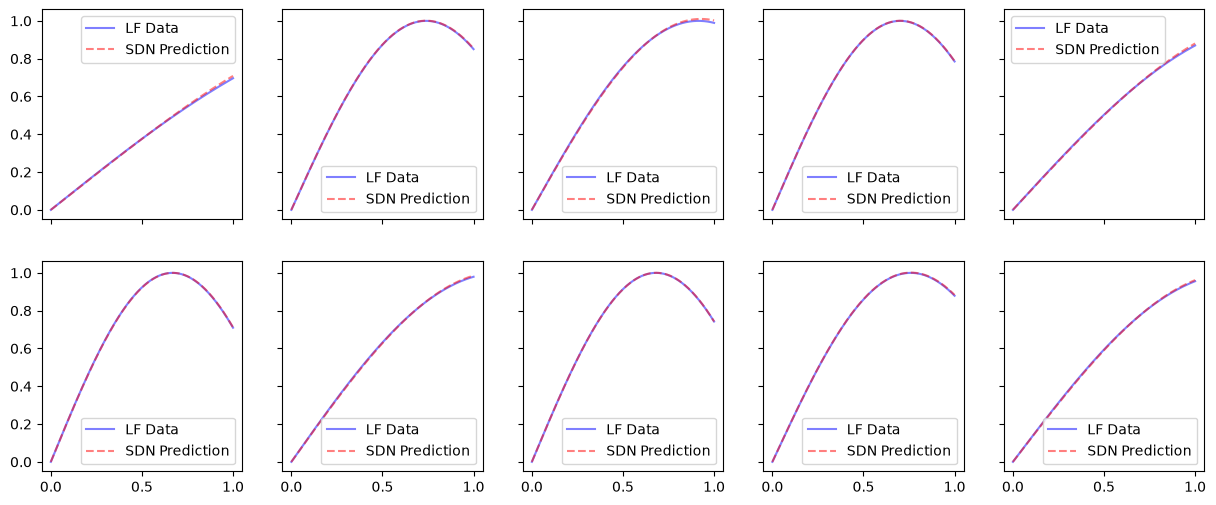

In [3]:
fig, axs = plt.subplots(2,5,figsize=(15, 6), sharey=True, sharex=True)
axs = axs.flatten()

for ii in range(len(axs)):
    fom = lf_test_dataset.Y.cpu().numpy()[ii]
    model_pred = lf_sdn(lf_test_dataset.X[ii]).cpu().detach().numpy()

    axs[ii].plot(x, fom, 'b', label='LF Data', alpha=0.5)
    axs[ii].plot(x, model_pred, 'r--', label='SDN Prediction', alpha=0.5)

    axs[ii].legend()

### Accuracy assessment with respect to the HF solution
Let us import the HF data and the LF for the corresponding parameters, and plot the results.

**This code assumes that the mesh for HF and LF is the same.**

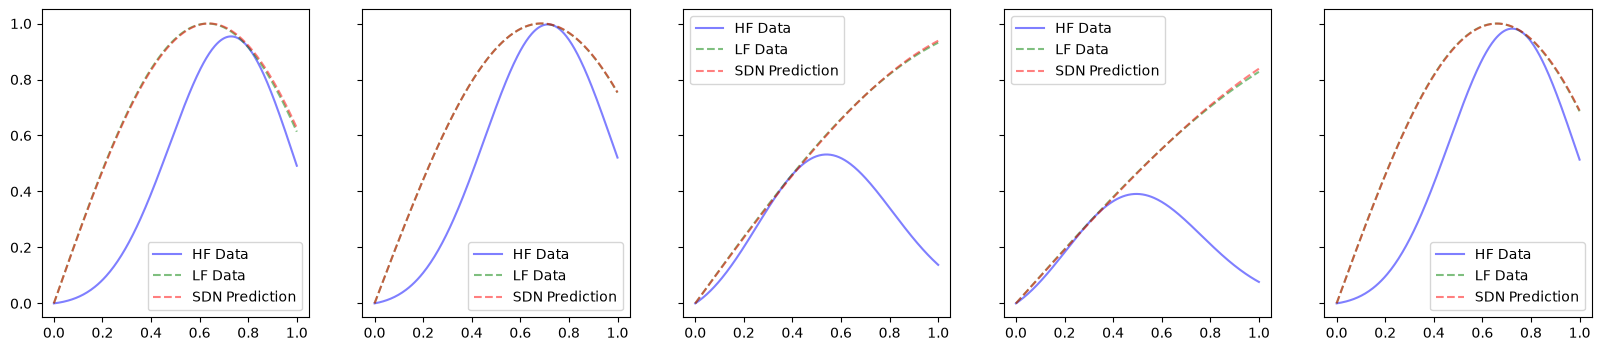

In [4]:
hf_params = np.linspace(mu_example[0]+0.1, mu_example[-1], 50).reshape(-1, 1)
hf_snaps = np.stack([u_HF(x, mu) for mu in hf_params]).T
hf_centroids = x.reshape(-1, 1)

lf_snaps_comparison = np.stack([u_LF(x, mu) for mu in hf_params]).T

_input = np.concatenate([lf_snaps_comparison[lf_idx_sens_locs], hf_params.T], axis=0)
_input = lf_input_scaler.transform(_input.T).T
_input = torch.tensor(_input, dtype=torch.float32).to(device).T
lf_sdn_pred = lf_sdn(_input).cpu().detach().numpy().T

params_to_plot = np.random.choice(np.arange(len(hf_params)), size=5, replace=False)
fig, axs = plt.subplots(1, 5, figsize=(20, 4), sharey=True, sharex=True)
axs = axs.flatten()

for ii, param in enumerate(params_to_plot):
    axs[ii].plot(x, hf_snaps[:, param], 'b', label='HF Data', alpha=0.5)
    axs[ii].plot(x, lf_snaps_comparison[:, param], 'g--', label='LF Data', alpha=0.5)
    axs[ii].plot(x, lf_sdn_pred[:, param], 'r--', label='SDN Prediction', alpha=0.5)
    
    axs[ii].legend()

## Mapping Low Fidelity to High Fidelity

In [5]:
np.random.seed(42)
hf_idx_params_lhs = np.random.choice(np.arange(len(hf_params)), size=30, replace=False)
hf_params_lhs = hf_params[hf_idx_params_lhs]
hf_snaps_lhs = hf_snaps[:, hf_idx_params_lhs]
lf_snaps_lhs = lf_snaps_comparison[:, hf_idx_params_lhs]

train_indices, test_indices = train_test_split(np.arange(len(hf_params_lhs)), test_size=0.6, random_state=42)
train_indices, valid_indices = train_test_split(train_indices, test_size=0.2, random_state=42)

print(train_indices.shape, test_indices.shape, valid_indices.shape)

(9,) (18,) (3,)


Defining the datasets

In [6]:
_input = np.concatenate([lf_snaps_lhs[lf_idx_sens_locs], hf_params_lhs.T], axis=0)
_input = lf_input_scaler.transform(_input.T).T
_input = torch.tensor(_input, dtype=torch.float32).to(device).T

# Obtain the reduced coefficients predicted by the SDN
lf_sdn_red_coeff = lf_sdn.forward_pod(_input).cpu().detach().numpy() # shape (Nsample, rank)

train_input = lf_sdn_red_coeff[train_indices]
test_input  = lf_sdn_red_coeff[test_indices]
valid_input = lf_sdn_red_coeff[valid_indices]

# Define the scaler
hf_input_scaler = MinMaxScaler()
hf_input_scaler.fit(train_input)

train_input = hf_input_scaler.transform(train_input)
test_input  = hf_input_scaler.transform(test_input)
valid_input = hf_input_scaler.transform(valid_input)

Define loss functions possibilities

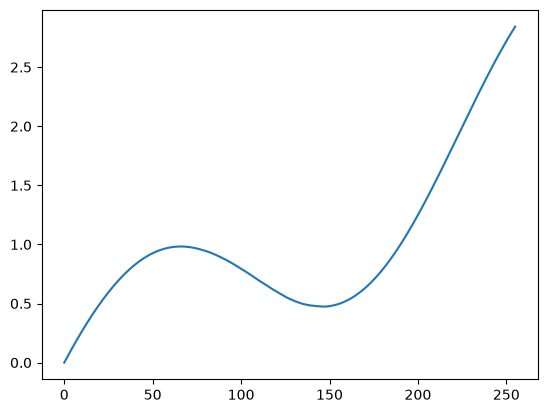

In [7]:
residuals = np.abs(hf_snaps_lhs[:, train_indices] - lf_sdn(_input)[train_indices].cpu().detach().numpy().T).mean(axis=1)
weight_mask = residuals / residuals.mean()

plt.plot(weight_mask)

from torch import nn

class WeightedL2Loss(nn.Module):
    def __init__(self, weight_mask=None):
        """
        Args:
            weight_mask: 1D tensor of shape [N] with spatial weights (optional).
                         Should sum to 1 or be normalized beforehand.
        """
        super().__init__()

        self.weight_mask = weight_mask

    def forward(self, pred_delta, true_delta):
        """
        Args:
            pred_delta: Tensor of shape [batch_size, N]
            true_delta: Tensor of shape [batch_size, N]
        Returns:
            Weighted L2 loss (scalar)
        """
        if self.weight_mask is not None:
            loss = ((pred_delta - true_delta) ** 2) * self.weight_mask.unsqueeze(0)
        else:
            loss = (pred_delta - true_delta) ** 2

        return loss.mean()
    
weight_mask = torch.tensor(weight_mask, dtype=torch.float32).to(device)

Define the network

In [8]:
import torch

class CorrectionDataset(torch.utils.data.Dataset):
    def __init__(self, v_LF, u_LF, u_HF):
        """
        v_LF: [num_samples, r]
        u_LF: [num_samples, Nh]
        u_HF: [num_samples, Nh]
        """
        self.v_LF = v_LF
        self.u_LF = u_LF
        self.u_HF = u_HF

    def __len__(self):
        return self.v_LF.shape[0]

    def __getitem__(self, idx):
        v_lf = self.v_LF[idx]
        u_lf = self.u_LF[idx]
        u_hf = self.u_HF[idx]
        return v_lf, u_lf, u_hf

class ResidualSDNetwork(nn.Module):
    def __init__(self, in_dim, out_dim, decoder_sizes = [350, 400], dropout = 0.0):
        super().__init__()

        self.decoder = torch.nn.ModuleList()
        decoder_sizes.insert(0, in_dim)
        decoder_sizes.append(out_dim)

        for i in range(len(decoder_sizes)-1):
            self.decoder.append(torch.nn.Linear(decoder_sizes[i], decoder_sizes[i+1]))
            if i != len(decoder_sizes)-2:
                self.decoder.append(torch.nn.Dropout(dropout))
                self.decoder.append(torch.nn.ReLU())

    def forward(self, x):
        output = x

        for layer in self.decoder:
            output = layer(output)

        return output
    
    def freeze(self):

        self.eval()
        
        for param in self.parameters():
            param.requires_grad = False

    def unfreeze(self):

        self.train()
        
        for param in self.parameters():
            param.requires_grad = True

# Define the datasets

train_delta_dataset = CorrectionDataset(
    torch.tensor(train_input, dtype=torch.float32).to(device),
    lf_sdn(_input)[train_indices].detach().clone(), 
    torch.tensor(hf_snaps_lhs[:, train_indices].T, dtype=torch.float32).to(device)
)
test_delta_dataset = CorrectionDataset(
    torch.tensor(test_input, dtype=torch.float32).to(device),
    lf_sdn(_input)[test_indices].detach().clone(),
    torch.tensor(hf_snaps_lhs[:, test_indices].T, dtype=torch.float32).to(device)
)
valid_delta_dataset = CorrectionDataset(
    torch.tensor(valid_input, dtype=torch.float32).to(device),
    lf_sdn(_input)[valid_indices].detach().clone(),
    torch.tensor(hf_snaps_lhs[:, valid_indices].T, dtype=torch.float32).to(device)
)

# Define the Residual SDN
in_dim = train_input.shape[1]
out_dim = hf_snaps_lhs.shape[0]
residual_sdn = ResidualSDNetwork(in_dim=in_dim, out_dim=out_dim, dropout=0.1, decoder_sizes=[350, 400]).to(device)

Train the network

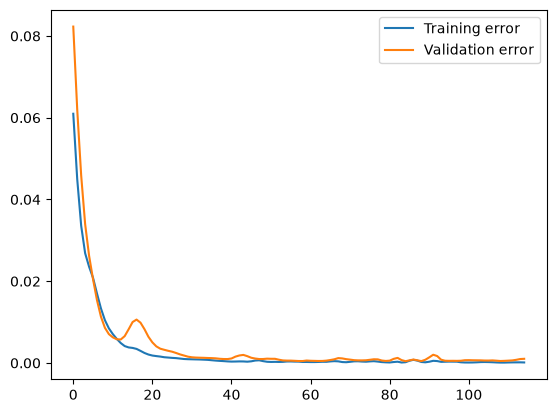

In [9]:
from utils.sdn import num2p, mre
from copy import deepcopy

def fit_res(model, train_dataset: CorrectionDataset, valid_dataset: CorrectionDataset,
          batch_size = 64, epochs = 4000, 
          optim = torch.optim.Adam, 
          criterion = torch.nn.MSELoss(),
          lr = 0.001, verbose = False, patience = 5):
    '''
        Neural networks training
        
        Inputs
            model (`torch.nn.Module`)
            training dataset (`torch.Tensor`)
            validation dataset (`torch.Tensor`)
            batch size (default to 64)
            number of epochs (default to 4000)
            optimizer (default to `torch.optim.Adam`)
            learning rate (default to 0.001)
            verbose parameter (default to False) 
            patience parameter (default to 5)
        '''
    
    train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    optimizer = optim(model.parameters(), lr=lr)

    train_error_list = []
    valid_error_list = []

    patience_counter = 0
    best_params = model.state_dict()

    for epoch in range(1, epochs+1):
        for k, data in enumerate(train_loader):
            model.train()
            def closure():
                outputs = model(data[0]) + data[1]  # Adding the LF output to the SDN output
                optimizer.zero_grad()
                loss = criterion(outputs, data[2])
                loss.backward()
                return loss
            optimizer.step(closure)
        model.eval()
        with torch.no_grad():
            # train_error = mre(train_dataset.u_HF, model(train_dataset.v_LF) + train_dataset.u_LF)
            # valid_error = mre(valid_dataset.u_HF, model(valid_dataset.v_LF) + valid_dataset.u_LF)
            train_error = criterion(train_dataset.u_HF, model(train_dataset.v_LF) + train_dataset.u_LF)
            valid_error = criterion(valid_dataset.u_HF, model(valid_dataset.v_LF) + valid_dataset.u_LF)
            train_error_list.append(train_error)
            valid_error_list.append(valid_error)
        if verbose:
            # print("Epoch "+ str(epoch) + ": Training loss = " + num2p(train_error_list[-1]) + " \t Validation loss = " + num2p(valid_error_list[-1]) + " "*10, end = "\r")
            print("Epoch "+ str(epoch) + f": Training loss = {float(train_error_list[-1]):.4e} Validation Loss {float(valid_error_list[-1]):.4e}", end = "\r")

        if valid_error == torch.min(torch.tensor(valid_error_list)):
            patience_counter = 0
            best_params = deepcopy(model.state_dict())
        else:
            patience_counter += 1

        if patience_counter == patience:
            model.load_state_dict(best_params)
            # train_error = mre(train_dataset.u_HF, model(train_dataset.v_LF) + train_dataset.u_LF)
            # valid_error = mre(valid_dataset.u_HF, model(valid_dataset.v_LF) + valid_dataset.u_LF)
            train_error = criterion(train_dataset.u_HF, model(train_dataset.v_LF) + train_dataset.u_LF)
            valid_error = criterion(valid_dataset.u_HF, model(valid_dataset.v_LF) + valid_dataset.u_LF)
            if verbose:      
                # print("Training done: Training loss = " + num2p(train_error) + " \t Validation loss = " + num2p(valid_error))
                print("Training done: " + f": Training loss = {float(train_error_list[-1]):.4e} Validation Loss {float(valid_error_list[-1]):.4e}", end = "\r")
            break
        
        for param_group in optimizer.param_groups:
            param_group['lr'] = 1e-3 * (0.5 ** (epoch // 100))
   
    return torch.tensor(train_error_list).detach().cpu().numpy(), torch.tensor(valid_error_list).detach().cpu().numpy()
 
loss_function = WeightedL2Loss(weight_mask=weight_mask)
loss_function = nn.MSELoss()
train_res_errors, valid_res_errors = fit_res(   model=residual_sdn, train_dataset=train_delta_dataset, valid_dataset=valid_delta_dataset,
                                                batch_size=32, epochs=500, patience=30,
                                                optim=torch.optim.Adam, criterion=loss_function, lr=0.001,
                                                verbose=True)

plt.plot(train_res_errors, label='Training error')
plt.plot(valid_res_errors, label='Validation error')
plt.legend()

### Tier B MF baselines (sanity check)
Same HF training split as the residual SDN. On this smooth problem GP-residual should be very competitive.


In [ ]:
import time
import pandas as pd
from utils.mf_baselines import (
    LinearMFCorrector,
    PODGPRResidualCorrector,
    CoKrigingMFCorrector,
    evaluate_mf_methods,
)

mf_pod_rank = train_input.shape[1]
v_lf_train = train_delta_dataset.v_LF
u_lf_train = train_delta_dataset.u_LF
u_hf_train = train_delta_dataset.u_HF
mu_train = hf_params_lhs[train_indices]

start = time.perf_counter()
linear_mf = LinearMFCorrector(alpha=1e-6).fit(v_lf_train, u_lf_train, u_hf_train)
linear_fit_s = time.perf_counter() - start

start = time.perf_counter()
gp_residual = PODGPRResidualCorrector(rank=mf_pod_rank, alpha=1e-4).fit(v_lf_train, u_lf_train, u_hf_train)
gp_fit_s = time.perf_counter() - start

start = time.perf_counter()
cokriging_mf = CoKrigingMFCorrector(rank=mf_pod_rank, alpha=1e-4).fit(mu_train, u_lf_train, u_hf_train)
cokrig_fit_s = time.perf_counter() - start

mf_costs = pd.DataFrame(
    {'fit [s]': [linear_fit_s, gp_fit_s, cokrig_fit_s]},
    index=['Linear-MF', 'GP-residual', 'Co-kriging'],
)
display(mf_costs)


Plot of the errors

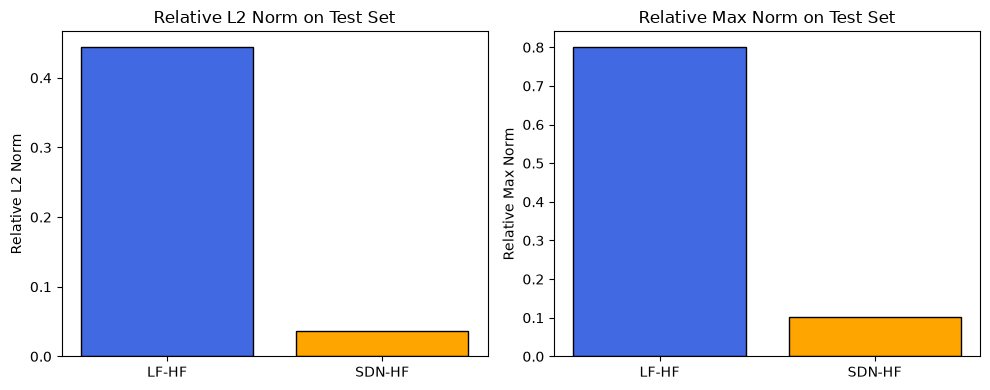

In [10]:
pred_sdn_mf = (residual_sdn(test_delta_dataset.v_LF) + test_delta_dataset.u_LF).cpu().detach().numpy().T
pred_linear_mf = linear_mf.predict(test_delta_dataset.v_LF, test_delta_dataset.u_LF).T
pred_gp_mf = gp_residual.predict(test_delta_dataset.v_LF, test_delta_dataset.u_LF).T
pred_ck_mf = cokriging_mf.predict(hf_params_lhs[test_indices], test_delta_dataset.u_LF).T
test_hf_fom = test_delta_dataset.u_HF.cpu().numpy().T
test_lf_fom = test_delta_dataset.u_LF.cpu().numpy().T

mf_test_metrics = evaluate_mf_methods(
    test_hf_fom,
    {
        'Linear-MF': pred_linear_mf,
        'GP-residual': pred_gp_mf,
        'Co-kriging': pred_ck_mf,
        'SDN-MF': pred_sdn_mf,
    },
    reference_lf=test_lf_fom,
)

methods = ['LF', 'Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF']
colors = ['royalblue', 'seagreen', 'goldenrod', 'purple', 'orange']
l2_vals = [mf_test_metrics[m]['l2'] for m in methods]
max_vals = [mf_test_metrics[m]['max'] for m in methods]

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].bar(methods, l2_vals, color=colors, edgecolor='black')
axs[0].set_ylabel('Relative $l_2$ norm')
axs[0].set_yscale('log')
axs[0].set_title('MF test split')
axs[0].tick_params(axis='x', rotation=20)

axs[1].bar(methods, max_vals, color=colors, edgecolor='black')
axs[1].set_ylabel('Relative $l_\infty$ norm')
axs[1].set_yscale('log')
axs[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

pd.DataFrame({k: {'rel-L2': v['l2'], 'rel-max': v['max']} for k, v in mf_test_metrics.items()}).T


Final Plot

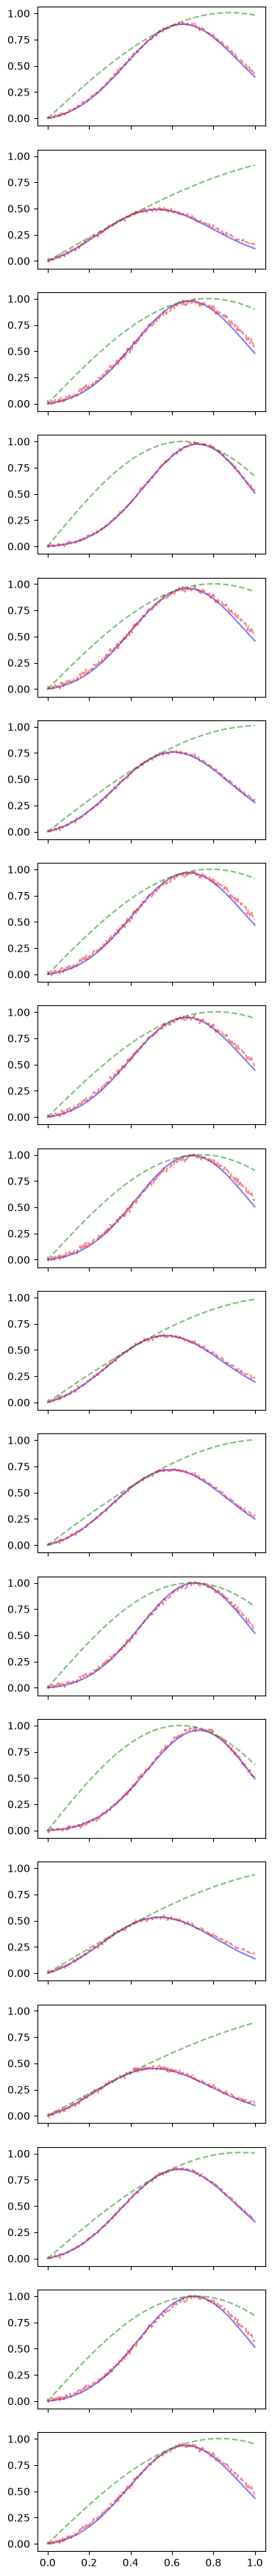

In [11]:
fig, axs = plt.subplots(len(test_indices), 1, figsize=(5, 2.5 * len(test_indices)), sharey=True, sharex=True)
if len(test_indices) == 1:
    axs = np.asarray([axs])

for ii, ax in enumerate(axs):
    ax.plot(x, test_hf_fom[:, ii], 'b', label='HF', alpha=0.7)
    ax.plot(x, test_lf_fom[:, ii], 'g--', label='LF', alpha=0.7)
    ax.plot(x, pred_gp_mf[:, ii], color='goldenrod', ls=':', label='GP-residual', alpha=0.9)
    ax.plot(x, pred_sdn_mf[:, ii], 'r--', label='SDN-MF', alpha=0.9)
    ax.set_ylabel(f'$\mu={hf_params_lhs[test_indices[ii], 0]:.2f}$', fontsize=10)

axs[0].legend(ncol=4, fontsize=9)
axs[-1].set_xlabel('$x$')
plt.tight_layout()
plt.show()
